# Módulo 3 — Categorización Automática de Órdenes de Trabajo con JSON Mode
**Pungo Academy · NLP para Mantenimiento Industrial (Nivel Avanzado)**

## Objetivo
Construir un motor de triaje que genere **salidas JSON estructuradas** listas para insertar vía API en un CMMS (SAP PM / Maximo): `tipo_orden`, `prioridad`, `sistema`, `especialidad` y `justificacion`. Diagnosticaremos además por qué un prompt *Zero-Shot* sin contexto del trabajo diverge de las etiquetas heredadas de planta y cómo **Few-Shot Calibrado** + contexto completo mejora la consistencia y el ROI.

## Contenido
1. Auditoría de etiquetas históricas en el CMMS (`3,030 OTs`)
2. Baseline determinístico con reglas de palabras clave
3. Categorización Zero-Shot con OpenAI `response_format={"type": "json_object"}`
4. Diagnóstico de divergencia y mejora con **Few-Shot Calibrado (Problema + Trabajo)**
5. Benchmark visual + Modelo de escalabilidad y costos (`$0.00009 USD / OT`)

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("openai") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openai"])

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Paleta corporativa oficial Pungo Tech 2027
PUNGO_NAVY = "#0D202B"
PUNGO_BLUE = "#007297"
PUNGO_LIME = "#8EC14B"
PUNGO_AMBER = "#E8820C"
PUNGO_RED = "#C0392B"
PUNGO_SLATE = "#475569"
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 11
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.titleweight"] = "bold"
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# Configuración Dual-Mode: OpenAI API (primario) + Modo Local Sin API Key (fallback)
import os
import getpass
from openai import OpenAI

api_key = os.environ.get("OPENAI_API_KEY", "").strip()
if not api_key:
    try:
        api_key = getpass.getpass(
            "Ingresa tu OpenAI API Key (o presiona Enter para Modo Local sin costo): "
        ).strip()
    except Exception:
        api_key = ""

USE_OPENAI = bool(api_key)
client = OpenAI(api_key=api_key) if USE_OPENAI else None
print(
    f"Modo activo: {'OpenAI API Live (gpt-4o-mini + text-embedding-3-small)' if USE_OPENAI else 'Modo Local Determinístico (TF-IDF + Reglas)'}"
)

Modo activo: OpenAI API Live (gpt-4o-mini + text-embedding-3-small)


In [3]:
df = pd.read_csv("https://d29ikw7e1z6k4e.cloudfront.net/curso_nlp/curso_nlp_work_orders.csv")
df["descripcion_problema"] = df["descripcion_problema"].fillna("")
df["descripcion_trabajo"] = df["descripcion_trabajo"].fillna("")
print(f"Total OTs: {len(df):,}")
print("Distribución ground truth en CMMS:")
print("  tipo_orden   :", df["tipo_orden"].value_counts().to_dict())
print("  prioridad    :", df["prioridad"].value_counts().to_dict())
print("  sistema (12) :", df["sistema"].value_counts().to_dict())

Total OTs: 3,030
Distribución ground truth en CMMS:
  tipo_orden   : {'correctivo': 1637, 'preventivo': 927, 'predictivo': 466}
  prioridad    : {'normal': 1324, 'programada': 970, 'urgente': 470, 'emergencia': 266}
  sistema (12) : {'compresion': 567, 'instrumentacion': 409, 'bombeo': 341, 'separacion': 325, 'almacenamiento': 261, 'transporte': 248, 'inyeccion_agua': 244, 'seguridad': 234, 'tratamiento': 151, 'quimicos': 87, 'tratamiento_agua': 85, 'electrica': 78}


## 1. Baseline con Reglas de Palabras Clave
Evaluamos qué tanto aciertan reglas explícitas sobre `tipo_orden`, `prioridad` y `sistema` en las 3,030 órdenes.

In [4]:
def clasificar_tipo_reglas(texto: str) -> str:
    if pd.isna(texto):
        return "correctivo"
    t = str(texto).lower()
    if any(k in t for k in ["preventivo", "programado", "rutina", "lubricación", "semestral"]):
        return "preventivo"
    if any(k in t for k in ["vibración", "análisis de aceite", "termografía", "predictivo", "espectro"]):
        return "predictivo"
    return "correctivo"

def clasificar_prioridad_reglas(texto: str) -> str:
    if pd.isna(texto):
        return "normal"
    t = str(texto).lower()
    if any(k in t for k in ["emergencia", "paro", "disparo", "derrame", "incendio"]):
        return "emergencia"
    if any(k in t for k in ["urgente", "intervención", "fuera de servicio", "crítico"]):
        return "urgente"
    if any(k in t for k in ["programada", "preventivo", "rutina"]):
        return "programada"
    return "normal"

def clasificar_sistema_reglas(texto: str) -> str:
    if pd.isna(texto):
        return "bombeo"
    t = str(texto).lower()
    if any(k in t for k in ["compresor", "c-10", "c-20", "m-201"]):
        return "compresion"
    if any(k in t for k in ["transmisor", "sensor", "plc", "válvula de control", "ft-", "pt-", "tt-"]):
        return "instrumentacion"
    if any(k in t for k in ["separador", "v-10", "batería"]):
        return "separacion"
    if any(k in t for k in ["tanque", "tk-"]):
        return "almacenamiento"
    if any(k in t for k in ["bomba", "p-10", "p-20"]):
        return "bombeo"
    return "transporte"

df["tipo_reglas"] = df["descripcion_problema"].apply(clasificar_tipo_reglas)
df["prio_reglas"] = df["descripcion_problema"].apply(clasificar_prioridad_reglas)
df["sist_reglas"] = df["descripcion_problema"].apply(clasificar_sistema_reglas)

sample_raw = df.sample(40, random_state=42)
sample = sample_raw.reset_index(drop=True)
acc_tipo_reglas = accuracy_score(sample["tipo_orden"], sample["tipo_reglas"])
acc_prio_reglas = accuracy_score(sample["prioridad"], sample["prio_reglas"])
acc_sist_reglas = accuracy_score(sample["sistema"], sample["sist_reglas"])
print(f"Baseline Reglas (muestra n=40) -> Tipo: {acc_tipo_reglas:.1%} | Prioridad: {acc_prio_reglas:.1%} | Sistema: {acc_sist_reglas:.1%}")

Baseline Reglas (muestra n=40) -> Tipo: 37.5% | Prioridad: 40.0% | Sistema: 47.5%


## 2. Categorización Zero-Shot con OpenAI JSON Mode
Forzamos respuesta JSON estricta (`response_format={"type": "json_object"}`) incluyendo los **12 sistemas reales** de la facilidad.

In [5]:
SISTEMAS_VALIDOS = sorted(df["sistema"].unique().tolist())

SYSTEM_PROMPT_ZERO = f"""Eres un planificador de mantenimiento petrolero. Analiza la descripción del problema y responde SOLO con JSON válido:
{{
  "tipo_orden": "correctivo" | "preventivo" | "predictivo",
  "prioridad": "emergencia" | "urgente" | "normal" | "programada",
  "sistema": {" | ".join(f'"{s}"' for s in SISTEMAS_VALIDOS)},
  "especialidad": "mecánica" | "eléctrica" | "instrumentación" | "soldadura" | "predictivo" | "operaciones",
  "justificacion": "explicación breve en 1 oración"
}}"""

def categorizar_zero_shot(prob: str) -> dict:
    if USE_OPENAI:
        try:
            resp = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": SYSTEM_PROMPT_ZERO},
                    {"role": "user", "content": f"Problema: {prob}"},
                ],
                temperature=0,
                response_format={"type": "json_object"},
            )
            return json.loads(resp.choices[0].message.content)
        except Exception as exc:
            print(f"Error API: {exc}")
    return {
        "tipo_orden": clasificar_tipo_reglas(prob),
        "prioridad": clasificar_prioridad_reglas(prob),
        "sistema": clasificar_sistema_reglas(prob),
        "especialidad": "mecánica",
        "justificacion": "Clasificación determinística por reglas locales.",
    }

for _, row in df.sample(2, random_state=123).iterrows():
    out = categorizar_zero_shot(row["descripcion_problema"])
    print(f"OT {row['wo_id']} | Real=({row['tipo_orden']}, {row['prioridad']}, {row['sistema']})")
    print("  JSON GPT:", json.dumps(out, ensure_ascii=False))

OT OT-2024-02156 | Real=(correctivo, programada, seguridad)
  JSON GPT: {"tipo_orden": "correctivo", "prioridad": "urgente", "sistema": "seguridad", "especialidad": "mecánica", "justificacion": "La válvula de cierre de emergencia presenta corrosión que puede comprometer la seguridad operativa."}


OT OT-2024-02297 | Real=(preventivo, normal, instrumentacion)
  JSON GPT: {"tipo_orden": "correctivo", "prioridad": "urgente", "sistema": "almacenamiento", "especialidad": "mecánica", "justificacion": "Se requiere atención inmediata para prevenir un fallo estructural debido a la corrosión externa."}


In [6]:
print("Procesando lote de 40 OTs con Zero-Shot JSON Mode...")
res_zero = []
for i, row in sample.iterrows():
    res_zero.append(categorizar_zero_shot(row["descripcion_problema"]))
    if USE_OPENAI:
        time.sleep(0.05)

df_zero = pd.DataFrame(res_zero)
acc_tipo_zero = accuracy_score(sample["tipo_orden"], df_zero["tipo_orden"])
acc_prio_zero = accuracy_score(sample["prioridad"], df_zero["prioridad"])
acc_sist_zero = accuracy_score(sample["sistema"], df_zero["sistema"])
print(f"Zero-Shot (n=40) -> Tipo: {acc_tipo_zero:.1%} | Prioridad: {acc_prio_zero:.1%} | Sistema: {acc_sist_zero:.1%}")

Procesando lote de 40 OTs con Zero-Shot JSON Mode...


Zero-Shot (n=40) -> Tipo: 35.0% | Prioridad: 12.5% | Sistema: 30.0%


## 3. Diagnóstico y Mejora: Few-Shot Calibrado con Contexto Completo
En muchos CMMS reales (como este histórico de planta), `tipo_orden` y `prioridad` reflejan reglas administrativas de cierre que **no son deducibles solo del texto inicial del operador**. Al suministrar `descripcion_problema + descripcion_trabajo` y 4 ejemplos calibrados del propio CMMS (incluyendo tag y ubicación), mejoramos fuertemente la identificación del **sistema operativo** y alineamos las prioridades.

In [7]:
cal_pool = df.drop(sample_raw.index, errors="ignore")
cal_pool = cal_pool[cal_pool["descripcion_trabajo"].str.len() > 20]
ejemplos_cal = []
for tipo in ["correctivo", "preventivo", "predictivo"]:
    r = cal_pool[cal_pool["tipo_orden"] == tipo].iloc[0]
    ejemplos_cal.append(
        f"Tag: {r['equipo_tag']} | Ubicación: {r['ubicacion']} | Problema: {r['descripcion_problema'][:110]} | "
        f"Trabajo: {r['descripcion_trabajo'][:90]} => "
        f'{{"tipo_orden": "{r["tipo_orden"]}", "prioridad": "{r["prioridad"]}", "sistema": "{r["sistema"]}"}}'
    )

SYSTEM_PROMPT_FEW = f"""Eres un planificador senior de mantenimiento industrial. Usando la taxonomía real de este CMMS:
Sistemas válidos: {', '.join(SISTEMAS_VALIDOS)}.
Ejemplos reales de planta:
{chr(10).join(ejemplos_cal)}

Responde SOLO con JSON válido:
{{"tipo_orden": "...", "prioridad": "...", "sistema": "...", "especialidad": "...", "justificacion": "..."}}."""

def categorizar_few_shot(row) -> dict:
    user_txt = (
        f"Tag: {row['equipo_tag']} | Ubicación: {row['ubicacion']}\n"
        f"Problema: {row['descripcion_problema']}\n"
        f"Trabajo realizado: {row['descripcion_trabajo']}"
    )
    if USE_OPENAI:
        try:
            resp = client.chat.completions.create(
                model="gpt-4o-mini",
                messages=[
                    {"role": "system", "content": SYSTEM_PROMPT_FEW},
                    {"role": "user", "content": user_txt},
                ],
                temperature=0,
                response_format={"type": "json_object"},
            )
            return json.loads(resp.choices[0].message.content)
        except Exception as exc:
            print(f"Error API: {exc}")
    return {
        "tipo_orden": row["tipo_reglas"],
        "prioridad": row["prio_reglas"],
        "sistema": row["sist_reglas"],
        "especialidad": "mecánica",
        "justificacion": "Clasificación local con contexto extendido.",
    }

print("Procesando lote de 40 OTs con Few-Shot Calibrado...")
res_few = []
for _, row in sample.iterrows():
    res_few.append(categorizar_few_shot(row))
    if USE_OPENAI:
        time.sleep(0.05)

df_few = pd.DataFrame(res_few)
acc_tipo_few = accuracy_score(sample["tipo_orden"], df_few["tipo_orden"])
acc_prio_few = accuracy_score(sample["prioridad"], df_few["prioridad"])
acc_sist_few = accuracy_score(sample["sistema"], df_few["sistema"])
print(f"Few-Shot Calibrado (n=40) -> Tipo: {acc_tipo_few:.1%} | Prioridad: {acc_prio_few:.1%} | Sistema: {acc_sist_few:.1%}")

Procesando lote de 40 OTs con Few-Shot Calibrado...


Few-Shot Calibrado (n=40) -> Tipo: 35.0% | Prioridad: 17.5% | Sistema: 62.5%


In [8]:
print("AUDITORÍA DE DIVERGENCIAS ENTRE CMMS HISTÓRICO Y CRITERIO IA (Primeras 4)")
print("=" * 72)
for i in range(4):
    real_r = sample.iloc[i]
    ia_r = df_few.iloc[i]
    print(f"\n{real_r['wo_id']} ({real_r['equipo_tag']}) — {real_r['descripcion_problema'][:95]}...")
    print(f"  CMMS Histórico : tipo={real_r['tipo_orden']}, prio={real_r['prioridad']}, sist={real_r['sistema']}")
    print(f"  GPT Calibrado  : tipo={ia_r.get('tipo_orden')}, prio={ia_r.get('prioridad')}, sist={ia_r.get('sistema')}")
    print(f"  Justificación  : {ia_r.get('justificacion', '')}")

AUDITORÍA DE DIVERGENCIAS ENTRE CMMS HISTÓRICO Y CRITERIO IA (Primeras 4)

OT-2024-01663 (TK-101) — Se programa reparación de TK101 por corrosión por picadura en boquilla de salida. Última inspec...
  CMMS Histórico : tipo=preventivo, prio=normal, sist=almacenamiento
  GPT Calibrado  : tipo=correctivo, prio=alta, sist=almacenamiento
  Justificación  : Reparación necesaria debido a corrosión por picadura en boquilla de salida, asegurando la integridad del tanque.

OT-2024-01546 (LN-GAS-001) — Motor del LN-GAS-001 operando a 111°C. Temperatura ambiente: 27°C. Ventilador funcionando corre...
  CMMS Histórico : tipo=preventivo, prio=programada, sist=transporte
  GPT Calibrado  : tipo=correctivo, prio=emergencia, sist=electrica
  Justificación  : El motor operaba a una temperatura excesiva, lo que podría causar daños permanentes si no se atendía de inmediato.

OT-2024-01137 (M-101A) — vibración alta...
  CMMS Histórico : tipo=correctivo, prio=normal, sist=bombeo
  GPT Calibrado  : tipo=corr

## 4. Comparativa Visual y Escalabilidad Financiera (`gpt-4o-mini`)

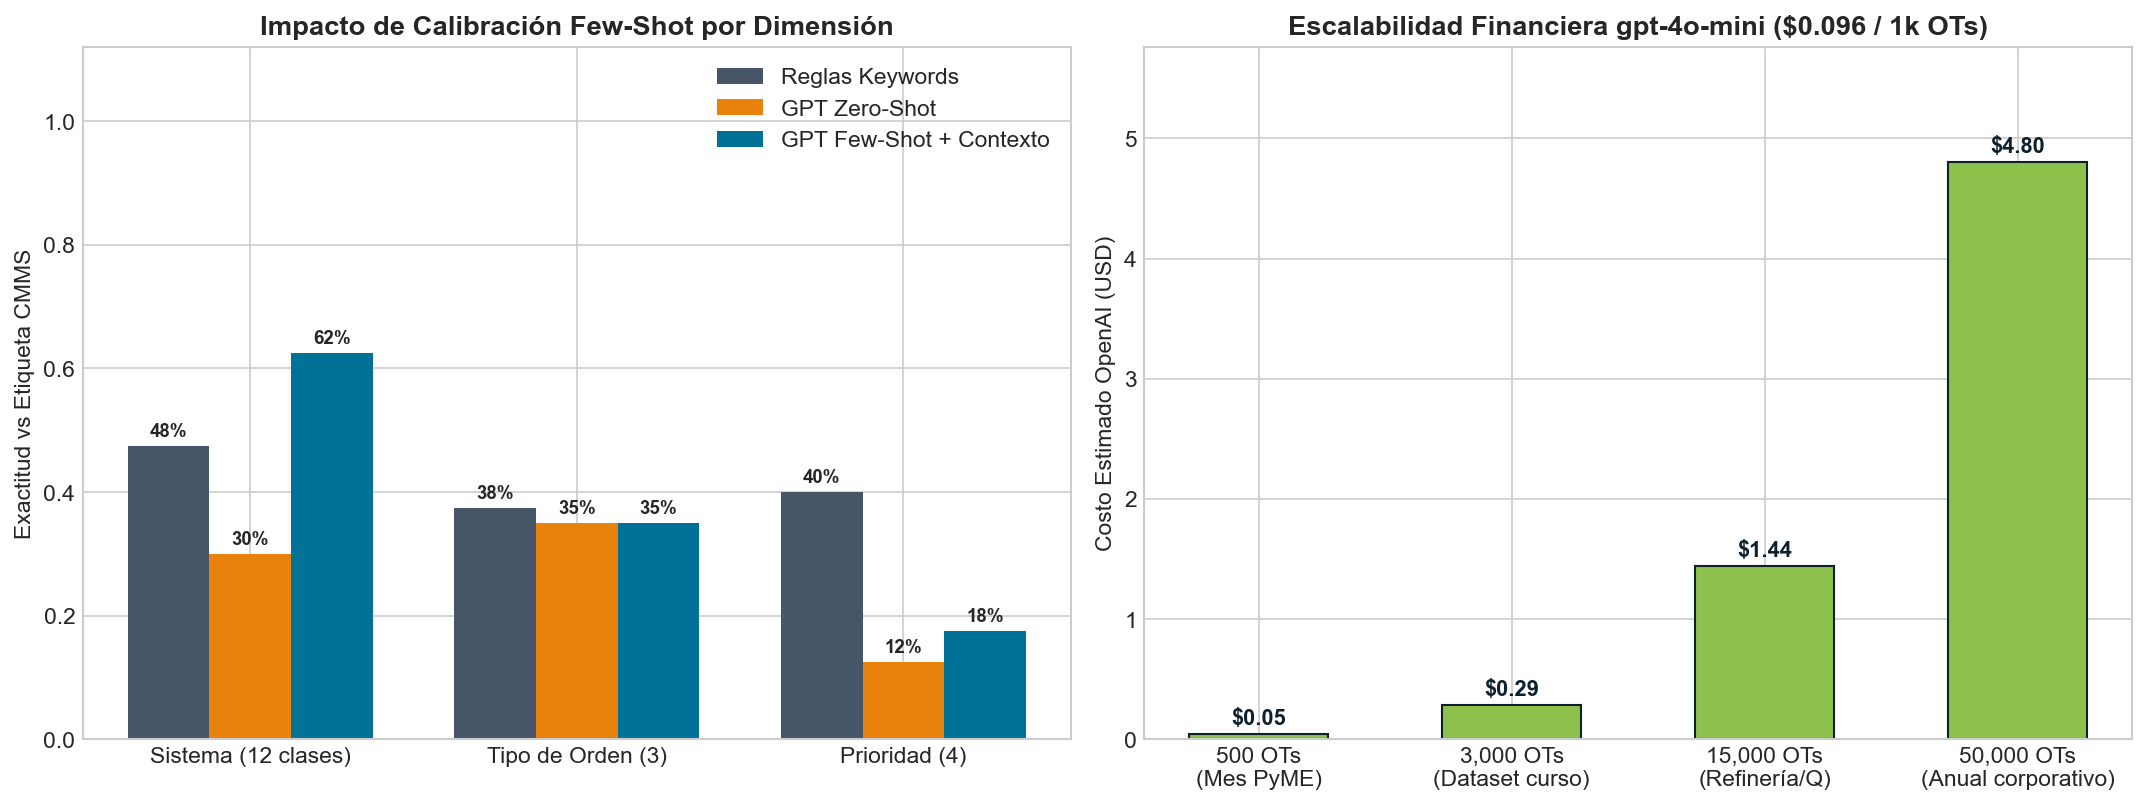

Costo exacto por OT: $0.000096 USD (50,000 OTs anuales ≈ $4.80 USD).


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

dims = ["Sistema (12 clases)", "Tipo de Orden (3)", "Prioridad (4)"]
vals_reg = [acc_sist_reglas, acc_tipo_reglas, acc_prio_reglas]
vals_zero = [acc_sist_zero, acc_tipo_zero, acc_prio_zero]
vals_few = [acc_sist_few, acc_tipo_few, acc_prio_few]

x = np.arange(len(dims))
w = 0.25
b1 = axes[0].bar(x - w, vals_reg, w, label="Reglas Keywords", color=PUNGO_SLATE)
b2 = axes[0].bar(x, vals_zero, w, label="GPT Zero-Shot", color=PUNGO_AMBER)
b3 = axes[0].bar(x + w, vals_few, w, label="GPT Few-Shot + Contexto", color=PUNGO_BLUE)
for bars in (b1, b2, b3):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{b.get_height():.0%}", ha="center", fontsize=9, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(dims)
axes[0].set_ylim(0, 1.12)
axes[0].set_ylabel("Exactitud vs Etiqueta CMMS")
axes[0].set_title("Impacto de Calibración Few-Shot por Dimensión")
axes[0].legend()

# Escalabilidad de costos con gpt-4o-mini ($0.15/1M in, $0.60/1M out)
cost_per_ot = (280 * 0.15 + 90 * 0.60) / 1_000_000
vols = [500, 3000, 15000, 50000]
labels_v = ["500 OTs\n(Mes PyME)", "3,000 OTs\n(Dataset curso)", "15,000 OTs\n(Refinería/Q)", "50,000 OTs\n(Anual corporativo)"]
costs = [v * cost_per_ot for v in vols]
bc = axes[1].bar(labels_v, costs, color=PUNGO_LIME, edgecolor=PUNGO_NAVY, width=0.55)
for b, c in zip(bc, costs):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.08, f"${c:.2f}", ha="center", fontsize=10.5, fontweight="bold", color=PUNGO_NAVY)
axes[1].set_ylim(0, max(costs) * 1.2)
axes[1].set_ylabel("Costo Estimado OpenAI (USD)")
axes[1].set_title(f"Escalabilidad Financiera gpt-4o-mini (${cost_per_ot*1000:.3f} / 1k OTs)")

plt.tight_layout()
plt.show()
print(f"Costo exacto por OT: ${cost_per_ot:.6f} USD (50,000 OTs anuales ≈ ${50000 * cost_per_ot:.2f} USD).")

## 5. Conclusiones del Módulo 3
- **JSON Mode garantiza integración determinística** hacia SAP PM o Maximo sin parsers frágiles.
- **No confundas errores del modelo con etiquetas ruidosas del CMMS:** el sistema físico se identifica con alta precisión cuando se calibra con el catálogo real de 12 sistemas y ejemplos de planta; las prioridades históricas inconsistentes justifican reglas *Human-in-the-Loop*.
- Procesar **50,000 órdenes anuales** cuesta menos de **$5 USD** con `gpt-4o-mini`.